In [ ]:
import pandas as pd

###Lectura inicial

In [ ]:
data = pd.read_csv("archive.zip")

In [ ]:
data

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
data.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:
print("Duplicados:", data.duplicated().sum())

print("Valores nulos:")
print(data.isnull().sum())

Duplicados: 0
Valores nulos:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [ ]:
columnas = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

print((data[columnas] == 0).sum())


Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


###Distribución de las variables

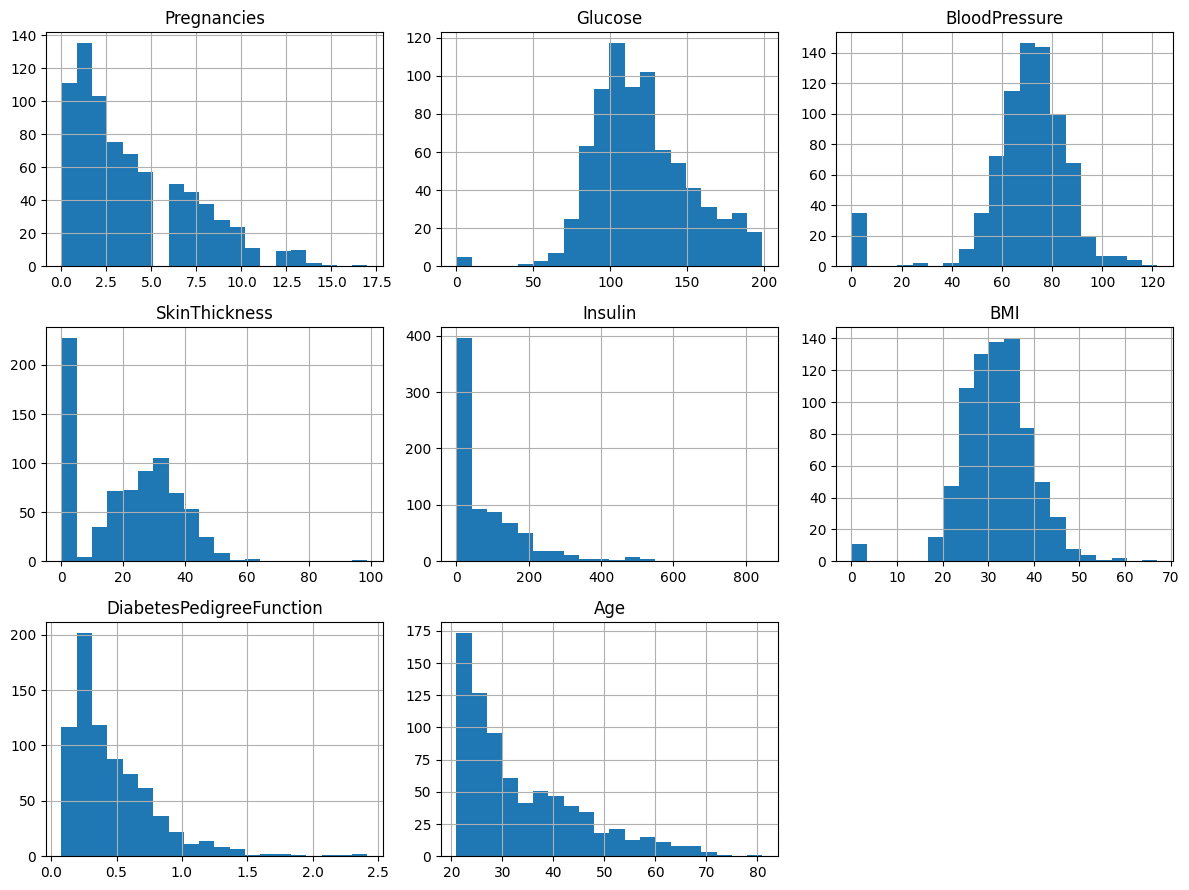

In [ ]:
import matplotlib.pyplot as plt

data.drop(columns="Outcome").hist(
    figsize=(12, 9),
    bins=20
)

plt.tight_layout()
plt.show()


###Distribución de la variable objetivo

Outcome
0    500
1    268
Name: count, dtype: int64


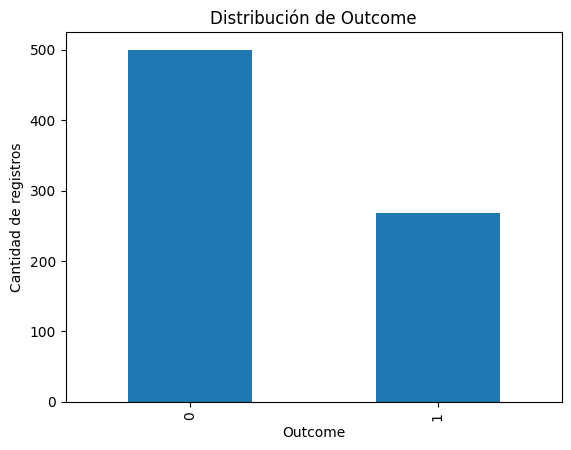

In [ ]:

print(data["Outcome"].value_counts())

data["Outcome"].value_counts().sort_index().plot(
    kind="bar",
    title="Distribución de Outcome"
)

plt.xlabel("Outcome")
plt.ylabel("Cantidad de registros")
plt.show()


### Relación de los predictores con la variable objetivo

In [ ]:
data.groupby("Outcome").mean().round(2)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Outcome,,,,,,,,
0,3.30,109.98,68.18,19.66,68.79,30.30,0.43,31.19
1,4.87,141.26,70.82,22.16,100.34,35.14,0.55,37.07


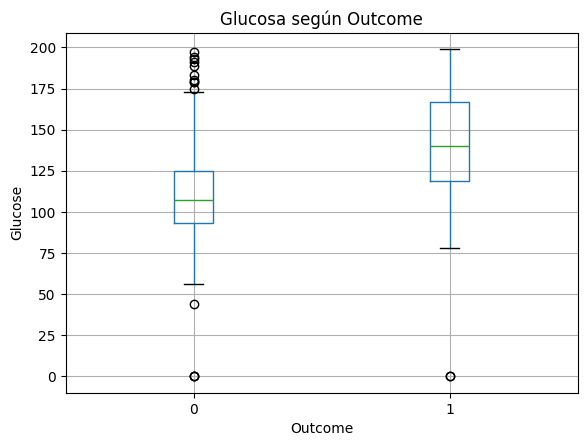

In [ ]:
data.boxplot(
    column="Glucose",
    by="Outcome"
)

plt.title("Glucosa según Outcome")
plt.suptitle("")
plt.xlabel("Outcome")
plt.ylabel("Glucose")
plt.show()

Los registros con Outcome = 1 presentan, en promedio, valores más elevados de glucosa, IMC y edad. Aunque los promedios todavía incluyen los 0

Reserva del lote de producción (15 %)

In [ ]:
from sklearn.model_selection import train_test_split

data_desarrollo, data_produccion = train_test_split(
    data,
    test_size=0.15,
    random_state=42,
    stratify=data["Outcome"]
)

print(data_desarrollo.shape)
print(data_produccion.shape)

(652, 9)
(116, 9)


Separar entrenamiento y evaluación

In [ ]:
data_entrenamiento, data_evaluacion = train_test_split(
    data_desarrollo,
    test_size=0.20,
    random_state=1234,
    stratify=data_desarrollo["Outcome"]
)

print("Entrenamiento:", data_entrenamiento.shape)
print("Evaluación:", data_evaluacion.shape)
print("Producción:", data_produccion.shape)

Entrenamiento: (521, 9)
Evaluación: (131, 9)
Producción: (116, 9)


Separamos las variables predictoras y la variable objetivo

In [ ]:
import numpy as np

# Separar predictores y variable objetivo
X_train = data_entrenamiento.drop(columns="Outcome").copy()
y_train = data_entrenamiento["Outcome"]

X_test = data_evaluacion.drop(columns="Outcome").copy()
y_test = data_evaluacion["Outcome"]

X_produccion = data_produccion.drop(columns="Outcome").copy()

# Columnas donde cero representa un posible faltante
columnas_ceros = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Reemplazar ceros por NaN en los tres conjuntos
for conjunto in [X_train, X_test, X_produccion]:
    conjunto[columnas_ceros] = conjunto[columnas_ceros].replace(0, np.nan)

# Comprobar el reemplazo en entrenamiento
print(X_train[columnas_ceros].isna().sum())



Glucose            4
BloodPressure     19
SkinThickness    150
Insulin          252
BMI                7
dtype: int64


Creación del pipeline de preparación

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

columnas_ceros = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

otras_columnas = [
    c for c in X_train.columns if c not in columnas_ceros
]

preprocesamiento = ColumnTransformer([
    ("imputacion", SimpleImputer(
    strategy="median"
), columnas_ceros),

    ("otras", "passthrough", otras_columnas)
])

pipeline_preparacion = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("escalado", StandardScaler())
])

\* Indicamos qué variables contienen ceros que podrían representar datos faltantes.


* Preparamos su reemplazo mediante la mediana.


* Incorporamos una estandarización para los modelos que la necesiten.


* Dejamos todas las transformaciones dentro de un pipeline.

In [ ]:
pipeline_preparacion_A = pipeline_preparacion

In [ ]:
# Alternativa B: excluir solamente Insulin

columnas_ceros_B = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "BMI"
]

otras_columnas_B = [
    "Pregnancies",
    "DiabetesPedigreeFunction",
    "Age"
]

preprocesamiento_B = ColumnTransformer([
    ("imputacion", SimpleImputer(
        strategy="median"
    ), columnas_ceros_B),

    ("otras", "passthrough", otras_columnas_B)
])

pipeline_preparacion_B = Pipeline([
    ("preprocesamiento", preprocesamiento_B),
    ("escalado", StandardScaler())
])

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Validación cruzada: conserva aproximadamente la proporción de Outcome
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

modelos = {
    "Regresión logística": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "K vecinos (KNN)": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(class_weight="balanced", probability=True),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

preprocesamientos = {
    "A (imputa ceros de Insulin)": pipeline_preparacion_A,
    "B (excluye Insulin)": pipeline_preparacion_B
}

resultados = []

for nombre_prep, prep in preprocesamientos.items():
    for nombre_modelo, modelo in modelos.items():
        pipeline = Pipeline([
            ("preparacion", clone(prep)),
            ("modelo", clone(modelo))
        ])

        scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring={
                "f1": "f1",
                "recall": "recall",
                "precision": "precision",
                "roc_auc": "roc_auc",
                "accuracy": "accuracy"
            },
            n_jobs=-1
        )

        resultados.append({
            "Preprocesamiento": nombre_prep,
            "Modelo": nombre_modelo,
            "F1 promedio": scores["test_f1"].mean(),
            "Recall promedio": scores["test_recall"].mean(),
            "Precisión promedio": scores["test_precision"].mean(),
            "ROC AUC promedio": scores["test_roc_auc"].mean(),
            "Accuracy promedio": scores["test_accuracy"].mean()
        })

tabla_resultados = (
    pd.DataFrame(resultados)
    .sort_values("F1 promedio", ascending=False)
    .reset_index(drop=True)
)

tabla_resultados.round(3)

,Preprocesamiento,Modelo,F1 promedio,Recall promedio,Precisión promedio,ROC AUC promedio,Accuracy promedio
0,B (excluye Insulin),Regresión logística,0.649,0.692,0.614,0.808,0.737
1,A (imputa ceros de Insulin),SVM,0.646,0.726,0.584,0.810,0.720
2,A (imputa ceros de Insulin),Regresión logística,0.645,0.687,0.611,0.808,0.735
3,B (excluye Insulin),SVM,0.635,0.715,0.573,0.805,0.712
4,A (imputa ceros de Insulin),K vecinos (KNN),0.574,0.550,0.608,0.770,0.718
5,B (excluye Insulin),K vecinos (KNN),0.566,0.533,0.607,0.757,0.714
6,A (imputa ceros de Insulin),Random Forest,0.565,0.523,0.619,0.791,0.720
7,B (excluye Insulin),Random Forest,0.556,0.506,0.621,0.784,0.716
8,B (excluye Insulin),Gradient Boosting,0.551,0.517,0.591,0.767,0.706
9,A (imputa ceros de Insulin),Gradient Boosting,0.550,0.512,0.597,0.783,0.708


Modelo: Regresión logística
Preprocesamiento: B (excluye Insulin)

Reporte de clasificación:
              precision    recall  f1-score   support

Sin diabetes       0.91      0.82      0.86        85
Con diabetes       0.72      0.85      0.78        46

    accuracy                           0.83       131
   macro avg       0.82      0.84      0.82       131
weighted avg       0.84      0.83      0.83       131

Matriz de confusión:
[[70 15]
 [ 7 39]]
ROC AUC en prueba: 0.91


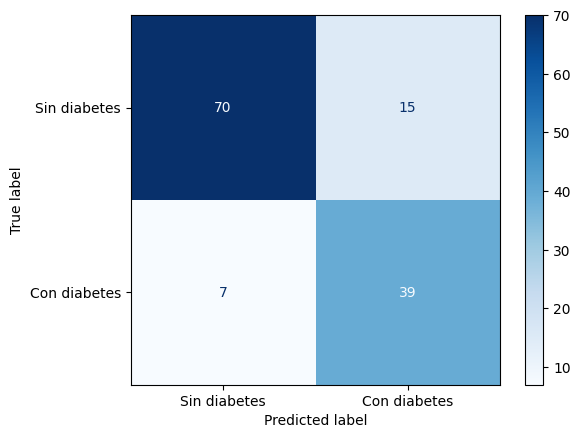

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)
import matplotlib.pyplot as plt

mejor_fila = tabla_resultados.iloc[0]
nombre_prep = mejor_fila["Preprocesamiento"]
nombre_modelo = mejor_fila["Modelo"]

mejor_prep = preprocesamientos[nombre_prep]
mejor_modelo = modelos[nombre_modelo]

modelo_final = Pipeline([
    ("preparacion", clone(mejor_prep)),
    ("modelo", clone(mejor_modelo))
])

modelo_final.fit(X_train, y_train)
y_pred = modelo_final.predict(X_test)

print(f"Modelo: {nombre_modelo}")
print(f"Preprocesamiento: {nombre_prep}")
print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred, target_names=["Sin diabetes", "Con diabetes"]))

print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred))

if hasattr(modelo_final, "predict_proba"):
    y_prob = modelo_final.predict_proba(X_test)[:, 1]
    print("ROC AUC en prueba:", round(roc_auc_score(y_test, y_prob), 3))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Sin diabetes", "Con diabetes"],
    cmap="Blues"
)
plt.show()